# 04 — Data Preparation and Feature Engineering (FD001)

**Project:** Predictive Intelligence · **Phase 4**

## Objective

Turn the raw sensor tables into inputs a model can learn from, and make every choice on evidence. The notebooks so far raised five questions; this one answers them:

1. How do we check a model honestly, without fooling ourselves?
2. Which columns do we keep?
3. Should the RUL label be capped, and at what value?
4. Which engineered features help?
5. How do we scale the data and cut it into windows for sequence models?

The reusable code is in `src/features/build.py` and `src/data/splits.py`. The decisions are logged in `docs/DECISIONS.md`.

**The test set is not used to make any decision in this notebook.** It appears only once, at the end, to confirm that the pipeline can process it.

> **Data note.** C-MAPSS is simulated turbofan data, not telemetry from real aircraft.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(project_root))

from src.data.cmapss import SENSOR_COLUMNS, SETTING_COLUMNS, add_training_rul, load_subset
from src.data.splits import engine_folds, holdout_engine_split
from src.evaluation.metrics import rmse
from src.features.build import add_baseline_change, add_rolling_features, cap_rul, make_windows
from src.visualization import theme

theme.apply_theme()
pd.set_option("display.max_columns", 30)

train, test, test_rul = load_subset("FD001")
train_labelled = add_training_rul(train)

## 2. Honest validation: split by engine, never by row

**Data leakage** means a model is checked on information it has, in effect, already seen. The score looks excellent and then collapses on genuinely new data. It is the most common way a predictive-maintenance study ends up reporting numbers that cannot be reproduced.

The main leakage risk here is how we hold data back for checking. Two neighbouring cycles of the same engine are almost identical. If we hold back *random rows*, the model trains on cycles 100 and 102 of an engine and is "tested" on cycle 101. It does not need to understand wear; it only needs to recognise the engine.

The correct approach is to hold back **whole engines**. That mirrors real use: the model will be applied to an engine it has never seen.

We use two engine-wise schemes:

- **5-fold cross-validation by engine** for the decisions in this notebook. The 100 engines are divided into 5 groups of 20; each group takes a turn as the validation set while the other 80 train the model. Five results are more trustworthy than one.
- **A fixed hold-out of 20 engines** (random seed 42) for later use, for example to decide when to stop training a neural network.

### Measuring the size of the leak

To show this is not a theoretical worry, we score the same model both ways. The model is a gradient-boosted tree regressor from scikit-learn, used throughout this notebook as a *measuring instrument*: it is fast, needs no scaling and handles non-linear patterns. It is not our final model.

In [2]:
varying_sensors = [name for name in SENSOR_COLUMNS if train[name].nunique() > 2]
RUL_CAP_FOR_DEMO = 125


def fit_and_score(frame, features, train_rows, validation_rows, cap=RUL_CAP_FOR_DEMO):
    # Train on one set of rows, predict the other, return predictions.
    model = HistGradientBoostingRegressor(random_state=0)
    model.fit(frame.iloc[train_rows][features], cap_rul(frame.iloc[train_rows]["rul"], cap))
    return model.predict(frame.iloc[validation_rows][features])


def mean_validation_rmse(frame, features, folds) -> float:
    scores = []
    for train_rows, validation_rows in folds:
        predicted = fit_and_score(frame, features, train_rows, validation_rows)
        truth = cap_rul(frame.iloc[validation_rows]["rul"], RUL_CAP_FOR_DEMO)
        scores.append(rmse(truth, predicted))
    return float(np.mean(scores))


# Two inputs: single-cycle readings, and features that summarise each engine's
# recent history (explained in section 6). History features change slowly from
# one cycle to the next, so neighbouring rows of an engine are near-duplicates.
history_frame = add_baseline_change(add_rolling_features(train_labelled, varying_sensors, 30), varying_sensors, 20)
history_features = varying_sensors + [c for c in history_frame.columns if c.endswith(("_mean30", "_std30", "_delta"))]

leak_demo = {}
for label, frame, features in [("single-cycle readings", train_labelled, varying_sensors),
                               ("history features", history_frame, history_features)]:
    leak_demo[label] = {
        "random rows (leaky)": mean_validation_rmse(
            frame, features, KFold(n_splits=5, shuffle=True, random_state=42).split(frame)),
        "whole engines (correct)": mean_validation_rmse(frame, features, engine_folds(frame)),
    }
leak_table = pd.DataFrame(leak_demo).T
leak_table["error understated by (%)"] = (1 - leak_table["random rows (leaky)"] / leak_table["whole engines (correct)"]) * 100
leak_table.round(2)

,random rows (leaky),whole engines (correct),error understated by (%)
single-cycle readings,18.14,18.70,3.03
history features,8.88,13.48,34.10


**Findings.**

- With **single-cycle readings**, the leak is small: about 3%. One noisy snapshot does not identify its engine well, so the model has little to memorise.
- With **history features**, the leak is large. Random-row validation reports an error of 8.9 cycles; the honest engine-wise figure is 13.5. The leaky check understates the error by about a third.
- The reason is the one given above. History features change slowly, so a held-back row has near-identical neighbours in the training data. The model looks them up instead of learning wear.

**Lesson.** The better the features describe an engine's history, the worse row-wise validation becomes. Sliding windows overlap even more than these features do, so for the deep-learning models the effect would be at least as large. Every result in this project uses engine-wise splits.

In [3]:
training_engines, validation_engines = holdout_engine_split(train_labelled)
print(f"Fixed hold-out: {len(training_engines)} training engines, {len(validation_engines)} validation engines")
print("Validation engines:", validation_engines.tolist())

Fixed hold-out: 80 training engines, 20 validation engines
Validation engines: [3, 5, 19, 22, 25, 26, 28, 34, 43, 51, 52, 53, 57, 60, 62, 72, 82, 93, 98, 100]


## 3. Which columns to keep

From notebook 01:

| Columns | Decision | Reason |
|---|---|---|
| `setting_1`, `setting_2`, `setting_3` | Drop for FD001 | One flight condition; settings carry no information here. They will be needed for FD002 and FD004. |
| Sensors 1, 5, 10, 16, 18, 19 | Drop | Exactly constant |
| Sensor 6 | Drop | Two values one rounding step apart |
| `cycle` (engine age) | Not used as a feature | Notebook 02: age alone predicts the fleet average, and in service an engine's age since new may not reflect its condition after maintenance |
| Sensors 9 and 14 | **Test below** | Informative on some engines, inconsistent on others |

That leaves 14 sensors, or 12 if the core speeds are dropped.

## 4. A fair yardstick for comparing options

Sections 5 and 6 compare alternatives. To compare fairly, every option is scored the same way: 5-fold cross-validation by engine, same model, same folds. We report RMSE (root mean squared error: roughly the typical size of a miss in cycles, with large misses counted more heavily) on two fixed sets of validation rows, always measured against the **true, uncapped** RUL:

- **Within 100 cycles of failure.** This is where predictions drive maintenance decisions.
- **Within 150 cycles of failure.** A wider view that includes the transition from healthy to worn.

Measuring against the true RUL on fixed rows matters. If each option were scored against its own capped label, a lower cap would always look better simply because it makes the task easier.

The ± value is the spread across the five folds. A difference smaller than that spread should not be trusted.

In [4]:
def cross_validated_rmse(frame: pd.DataFrame, features: list[str], cap: int | None) -> dict:
    near_failure, wider = [], []
    for train_rows, validation_rows in engine_folds(frame):
        predicted = fit_and_score(frame, features, train_rows, validation_rows, cap=cap)
        true_rul = frame.iloc[validation_rows]["rul"].to_numpy()
        near_failure.append(rmse(true_rul[true_rul <= 100], predicted[true_rul <= 100]))
        wider.append(rmse(true_rul[true_rul <= 150], predicted[true_rul <= 150]))
    return {
        "RMSE within 100 cycles": np.mean(near_failure), "± (100)": np.std(near_failure),
        "RMSE within 150 cycles": np.mean(wider), "± (150)": np.std(wider),
    }

## 5. Capping the RUL label

**The problem.** The raw label falls in a straight line from the engine's total life down to zero. But notebook 03 showed that beyond roughly 125–150 cycles before failure, the sensors look the same whatever the remaining life. Training on the straight-line label asks the model to output 300 for one healthy engine and 180 for another when their readings are indistinguishable. The model cannot do it, and the effort distorts its predictions everywhere else.

**The idea.** Cap the label: every cycle with more than *C* cycles remaining is labelled *C*, meaning "healthy, no measurable wear yet". Below the cap the label counts down as before. This is called a piecewise-linear RUL target.

**When not to use it.** If the sensors did show steady change from the very first cycle, capping would throw away real information. It also means the model can never predict more than *C*, so the system must describe such engines as "at least *C* cycles" and not as "exactly *C*".

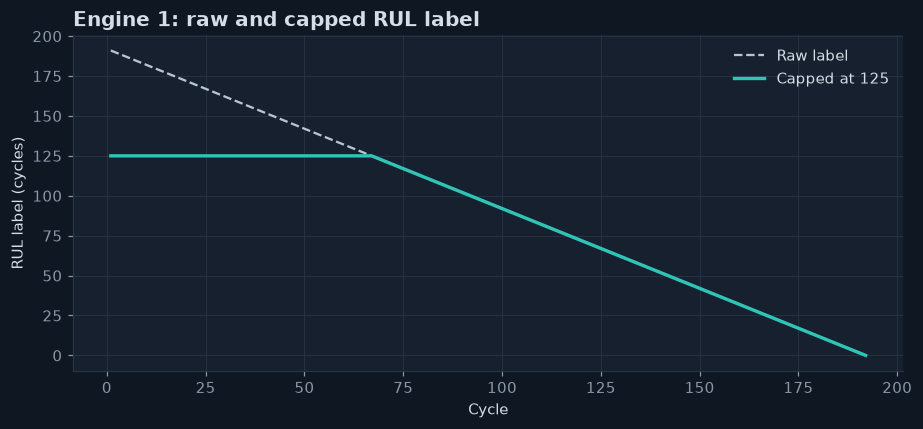

In [5]:
example = train_labelled[train_labelled["engine_id"] == 1]

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(example["cycle"], example["rul"], color=theme.SILVER, linestyle="--", label="Raw label")
ax.plot(example["cycle"], cap_rul(example["rul"], 125), color=theme.TEAL, linewidth=2.2, label="Capped at 125")
ax.set_title("Engine 1: raw and capped RUL label")
ax.set_xlabel("Cycle")
ax.set_ylabel("RUL label (cycles)")
ax.legend()
fig.tight_layout()
plt.show()

In [6]:
cap_results = {
    ("no cap" if cap is None else f"cap {cap}"): cross_validated_rmse(train_labelled, varying_sensors, cap)
    for cap in [None, 150, 130, 125, 115, 100]
}
cap_table = pd.DataFrame(cap_results).T
cap_table.round(2)

,RMSE within 100 cycles,± (100),RMSE within 150 cycles,± (150)
no cap,32.64,4.56,32.57,3.06
cap 150,26.01,3.19,24.65,1.68
cap 130,22.67,2.52,22.70,1.26
cap 125,21.70,2.37,22.45,1.19
cap 115,19.68,2.04,22.59,1.19
cap 100,16.60,1.43,24.53,1.05


**Findings.**

- **Not capping is clearly worst**: about 33 cycles of error on both yardsticks, against about 22 with a cap of 125. The model wastes its capacity on the unanswerable early-life question.
- **Caps between 115 and 130 are indistinguishable on the wider yardstick** (22.5 to 22.7, well inside the fold-to-fold spread of about 1.2).
- **A cap of 100 is too low**: error within 150 cycles rises again to 24.5, because engines with 100 to 150 cycles left can no longer be told apart.
- The "within 100 cycles" column keeps improving as the cap falls. Part of that is mechanical: a model capped at 100 can never overshoot above 100. That is why we do not choose on that column alone.

**Decision: cap at 125.** It sits in the flat best region of the wider yardstick, agrees with the detectability analysis in notebook 03 (wear is weakly visible beyond about 125 to 150 cycles), and is the value most often used in published work on this dataset, which keeps our later results comparable with the literature. A cap of 115 or 130 would be equally defensible on this evidence.

**Consequence to remember.** A prediction of 125 means "at least about 125 cycles; no measurable wear yet", not "exactly 125".

## 6. Engineered features

A single row of raw readings is one noisy snapshot. Notebook 03 showed that the information is in the *trend* and in the *departure from the engine's own normal*. Two kinds of feature make those visible to a model that looks at one row at a time.

**Rolling statistics.** For each sensor, the mean and the standard deviation over the engine's most recent *w* cycles. The mean is a smoothed reading; the standard deviation says how unsettled recent readings are. Longer windows smooth more but react later.

**Change from the engine's own baseline.** For each sensor, the current reading minus that engine's average over its first 20 cycles. Notebook 03 found that 28–86% of healthy-period variation is simply engines differing from one another. This feature removes it: it says "this engine's Ps30 is 0.4 above *its own* normal", not just "Ps30 is 47.8".

**Both are causal.** A value at cycle *t* uses only cycles 1 to *t* of the same engine. The check below proves it: if we cut every engine off at cycle 60 and recompute, the features for cycles 1–60 must be identical. If any feature peeked at the future, they would differ.

**Limits.** Baseline features need the engine's early cycles to be on record. That holds for every engine in C-MAPSS, including the test set, but would not hold for an engine whose monitoring started mid-life. Rolling features are less reliable in an engine's first few cycles, when the window is not yet full.

In [7]:
BASELINE_CYCLES = 20

full_history = add_baseline_change(add_rolling_features(train_labelled, varying_sensors, 30), varying_sensors, BASELINE_CYCLES)
truncated_history = train_labelled[train_labelled["cycle"] <= 60]
truncated_features = add_baseline_change(add_rolling_features(truncated_history, varying_sensors, 30), varying_sensors, BASELINE_CYCLES)

engineered_columns = [c for c in full_history.columns if c.endswith(("_mean30", "_std30", "_delta"))]
unchanged = np.allclose(full_history.loc[truncated_history.index, engineered_columns], truncated_features[engineered_columns])
print(f"{len(engineered_columns)} engineered columns")
print("Features for cycles 1-60 are identical with and without the engine's later cycles:", unchanged)
print("Missing values in engineered columns:", int(full_history[engineered_columns].isna().sum().sum()))

42 engineered columns
Features for cycles 1-60 are identical with and without the engine's later cycles: True
Missing values in engineered columns: 0


In [8]:
CHOSEN_CAP = 125
twelve_sensors = [name for name in varying_sensors if name not in ("sensor_9", "sensor_14")]


def columns_ending(frame: pd.DataFrame, suffixes: tuple[str, ...]) -> list[str]:
    return [name for name in frame.columns if name.endswith(suffixes)]


with_roll10 = add_rolling_features(train_labelled, varying_sensors, 10)
with_roll30 = add_rolling_features(train_labelled, varying_sensors, 30)
with_delta = add_baseline_change(train_labelled, varying_sensors, BASELINE_CYCLES)
with_all = add_baseline_change(with_roll30, varying_sensors, BASELINE_CYCLES)
with_all_12 = add_baseline_change(add_rolling_features(train_labelled, twelve_sensors, 30), twelve_sensors, BASELINE_CYCLES)

feature_sets = {
    "A. 14 raw sensors": (train_labelled, varying_sensors),
    "B. 12 raw sensors (no S9, S14)": (train_labelled, twelve_sensors),
    "C. A + rolling mean/std, 10 cycles": (with_roll10, varying_sensors + columns_ending(with_roll10, ("_mean10", "_std10"))),
    "D. A + rolling mean/std, 30 cycles": (with_roll30, varying_sensors + columns_ending(with_roll30, ("_mean30", "_std30"))),
    "E. A + change from baseline": (with_delta, varying_sensors + columns_ending(with_delta, ("_delta",))),
    "F. A + rolling 30 + change from baseline": (with_all, varying_sensors + columns_ending(with_all, ("_mean30", "_std30", "_delta"))),
    "G. F without S9, S14": (with_all_12, twelve_sensors + columns_ending(with_all_12, ("_mean30", "_std30", "_delta"))),
}

feature_results = {}
for name, (frame, features) in feature_sets.items():
    feature_results[name] = {"features": len(features), **cross_validated_rmse(frame, features, CHOSEN_CAP)}
feature_table = pd.DataFrame(feature_results).T
feature_table.round(2)

,features,RMSE within 100 cycles,± (100),RMSE within 150 cycles,± (150)
A. 14 raw sensors,14.0,21.70,2.37,22.45,1.19
"B. 12 raw sensors (no S9, S14)",12.0,23.96,2.03,24.77,0.88
"C. A + rolling mean/std, 10 cycles",42.0,21.64,2.73,22.71,1.79
"D. A + rolling mean/std, 30 cycles",42.0,18.91,1.80,21.25,0.98
E. A + change from baseline,28.0,15.83,0.82,17.60,0.59
F. A + rolling 30 + change from baseline,56.0,15.18,0.78,17.22,0.74
"G. F without S9, S14",48.0,16.46,1.59,18.38,1.34


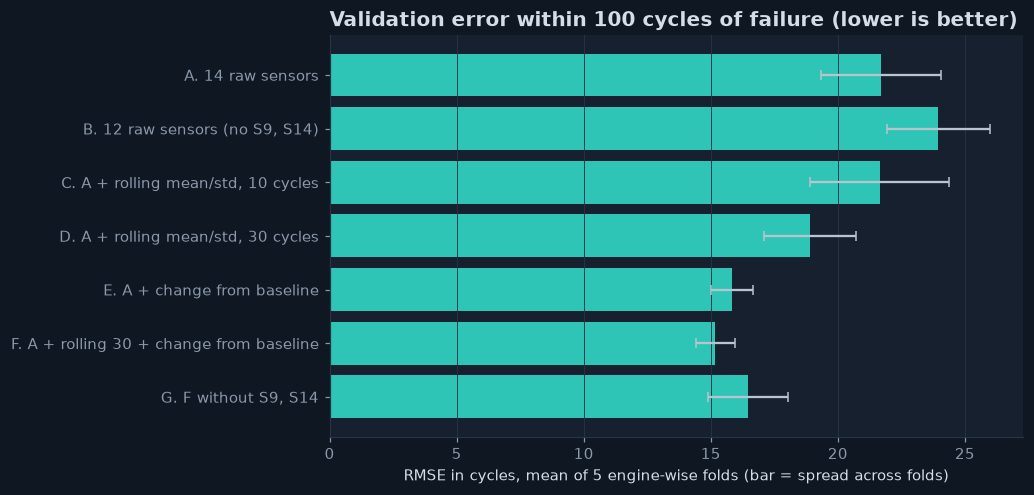

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
positions = np.arange(len(feature_table))
ax.barh(positions, feature_table["RMSE within 100 cycles"], xerr=feature_table["± (100)"],
        color=theme.TEAL, ecolor=theme.SILVER, capsize=3)
ax.set_yticks(positions, feature_table.index)
ax.invert_yaxis()
ax.set_title("Validation error within 100 cycles of failure (lower is better)")
ax.set_xlabel("RMSE in cycles, mean of 5 engine-wise folds (bar = spread across folds)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**Findings.**

- **Change from baseline is the largest single improvement.** Adding it to the raw sensors cuts the error within 100 cycles from 21.7 to 15.8, a reduction of about 27%, far larger than the fold spread. This confirms what notebook 03 suggested: much of the difficulty is that engines start at different levels.
- **A short rolling window adds nothing** (10 cycles: 21.6 against 21.7). **A 30-cycle window helps** (18.9), consistent with notebook 03's finding that the noise needs many cycles to average out.
- **Combining both gives the best result** (15.2 within 100 cycles, 17.2 within 150). The gain over baseline-change alone is small, about the size of the fold spread, so it is a modest improvement, not a decisive one.
- **Keep S9 and S14.** Removing the core speeds makes things worse in both comparisons (A to B: 21.7 to 24.0; F to G: 15.2 to 16.5). Their direction is inconsistent between engines, but a tree model can still use them in combination with other sensors. Whether models rely on them sensibly is a question for the explainability phase.
- The better feature sets are also more *consistent*: the fold spread falls from about 2.4 to about 0.8.

**Decision.** Tabular models use feature set **F**: 14 sensors, their 30-cycle rolling mean and standard deviation, and their change from the engine's 20-cycle baseline (56 features).

**Caveat.** These comparisons used one model type with default settings. A different model might rank the options somewhat differently, and the choice of 20 baseline cycles and a 30-cycle window was not tuned exhaustively.

## 7. Scaling

Sensors live on very different scales: core speed is around 9,000 rpm, bypass ratio around 8.4. Tree models do not care. Linear models and neural networks do: without scaling, large-valued sensors dominate and training becomes slow or unstable.

**Standard scaling** subtracts a mean and divides by a standard deviation, so each feature ends up centred on 0 with a spread of about 1. Notebook 03 found the sensor noise close to a bell curve with no outliers, which is the situation standard scaling suits. With heavy outliers a robust scaler would be the better choice.

**The leakage rule.** The mean and standard deviation are *learned from data*, so they must be learned from training engines only and then applied unchanged to validation and test engines. Computing them on everything would let information about the validation engines seep into training.

In [10]:
training_rows = train_labelled["engine_id"].isin(training_engines)

scaler = StandardScaler().fit(train_labelled.loc[training_rows, varying_sensors])   # training engines only
scaled_training = scaler.transform(train_labelled.loc[training_rows, varying_sensors])
scaled_validation = scaler.transform(train_labelled.loc[~training_rows, varying_sensors])

pd.DataFrame({
    "training mean": scaled_training.mean(axis=0),
    "training sd": scaled_training.std(axis=0),
    "validation mean": scaled_validation.mean(axis=0),
    "validation sd": scaled_validation.std(axis=0),
}, index=varying_sensors).round(3).T

,sensor_2,sensor_3,sensor_4,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
training mean,0.000,0.000,0.000,0.000,-0.000,0.000,0.000,-0.000,-0.000,0.000,-0.000,0.000,-0.000,0.000
training sd,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
validation mean,-0.005,-0.002,-0.012,0.009,-0.014,0.100,-0.002,0.019,-0.027,0.115,0.008,0.005,0.010,-0.000
validation sd,1.000,1.009,1.007,0.982,1.033,1.241,0.997,0.990,1.031,1.253,1.002,1.000,0.997,0.992


**Reading the table.** The training columns are exactly 0 and 1 by construction. The validation columns are close to, but not exactly, 0 and 1. That small mismatch is correct: it is what applying a scaler to genuinely unseen engines looks like.

## 8. Sliding windows for sequence models

Tree and linear models look at one row at a time, which is why they need the engineered features above. Sequence models (LSTM, GRU, TCN in Phase 6) take a different input: a block of consecutive cycles, from which they learn the trend themselves.

**Construction.** Slide a window of *w* cycles along each engine's history, one cycle at a time. Each window becomes one training example, labelled with the RUL at its **last** cycle. An engine with 192 cycles and a window of 30 gives 163 examples.

**Choosing the length.** Longer windows show more trend and average more noise, but every test engine needs at least that much history. Notebook 01 found the shortest test history is 31 cycles, so **30** is the longest window that needs no padding for any test engine. Whether a different length works better is an experiment for Phase 9. The function still pads shorter histories (by repeating the first reading), so the pipeline will not break on a short-history engine.

**For scoring an engine** we use only its most recent window: the latest 30 cycles are what we know at the moment a prediction is requested.

In [11]:
WINDOW_LENGTH = 30

prepared = train_labelled.copy()
prepared[varying_sensors] = scaler.transform(prepared[varying_sensors])
prepared["rul_capped"] = cap_rul(prepared["rul"], CHOSEN_CAP)

train_windows, train_targets, train_window_engines = make_windows(
    prepared[training_rows], varying_sensors, WINDOW_LENGTH, label_column="rul_capped")
validation_windows, validation_targets, _ = make_windows(
    prepared[~training_rows], varying_sensors, WINDOW_LENGTH, label_column="rul_capped")

print("Training windows:  ", train_windows.shape, " (examples, cycles per window, sensors)")
print("Validation windows:", validation_windows.shape)

# Check one window by hand: the first window of the first training engine.
first_engine = prepared[prepared["engine_id"] == train_window_engines[0]]
print("First window equals that engine's cycles 1-30:",
      np.allclose(train_windows[0], first_engine[varying_sensors].to_numpy()[:WINDOW_LENGTH]))
print("Its label equals the capped RUL at cycle 30:  ",
      train_targets[0] == first_engine["rul_capped"].iloc[WINDOW_LENGTH - 1])

Training windows:   (14459, 30, 14)  (examples, cycles per window, sensors)
Validation windows: (3272, 30, 14)
First window equals that engine's cycles 1-30: True
Its label equals the capped RUL at cycle 30:   True


### Confirming the pipeline handles the test set

The test engines go through the same steps with the *training* scaler. We take only the last window of each engine. No test label is used.

In [12]:
test_prepared = test.copy()
test_prepared[varying_sensors] = scaler.transform(test_prepared[varying_sensors])
test_windows, _, test_window_engines = make_windows(test_prepared, varying_sensors, WINDOW_LENGTH, last_only=True)

print("Test windows:", test_windows.shape, "- one per test engine")
print("Shortest test history:", test.groupby("engine_id").size().min(), "cycles, so no padding was needed")

Test windows: (100, 30, 14) - one per test engine
Shortest test history: 31 cycles, so no padding was needed


## 9. Decisions made in this notebook

| Topic | Decision | Evidence |
|---|---|---|
| Validation | Whole engines only: 5-fold by engine for comparisons, fixed 20-engine hold-out (seed 42) | Row-wise validation understated error by 34% with history features |
| Columns | Drop the 3 settings, sensors 1, 5, 6, 10, 16, 18, 19; do not use `cycle` | Constant or uninformative on FD001 |
| Sensors 9 and 14 | Keep | Removing them raised error in both comparisons |
| RUL label | Capped at 125 | No cap: about 33 cycles error; caps 115 to 130: about 22.5 |
| Tabular features | 14 sensors + 30-cycle rolling mean and sd + change from 20-cycle baseline (56 features) | Error within 100 cycles: 21.7 to 15.2 |
| Scaling | Standard scaling, fitted on training engines only | Near-Gaussian noise (notebook 03) |
| Sequence windows | 30 cycles, label = RUL at the last cycle | Shortest test history is 31 cycles |

All of these are recorded in `docs/DECISIONS.md` (D-006 to D-011), and the chosen values live in `src/config.py` so later notebooks cannot drift from them.

One observation from the scaling table: on the hold-out engines, sensors 9 and 14 have a noticeably larger spread (about 1.24) than on the training engines. That is the engine-to-engine irregularity of the core speeds showing up again, in a random group of 20 engines.

**Limitations.** Decisions were made on FD001 only, with one probe model. The multi-condition subsets will need the settings back and a different normalisation. The RUL cap changes what the model can say about healthy engines.

## 10. Next steps

**Notebook 05 - Traditional machine learning.** Train Linear Regression, Random Forest and XGBoost on these features, compare them by engine-wise cross-validation using RMSE, MAE and the NASA score, and only then score the chosen configurations once on the test set.